# ICU labels from an OMOP CDM

This tutorial derives the labels of common ICU benchmarks from a clinical database in the OMOP Common Data Model (CDM): the SOFA score of organ failure, the onset of sepsis by the Sepsis-3 definition and the KDIGO stage of acute kidney injury.
It then trains a model that predicts acute kidney injury from the first 24 hours of an ICU stay.

The data is the MIMIC-IV demo in the OMOP CDM, 100 patients that ehrdata downloads from [PhysioNet](https://physionet.org/content/mimic-iv-demo-omop/0.9/).
ehrdata reads the ICU stays and their measurements into an {class}`~ehrdata.EHRData`, and ehrapy computes the labels and fits the model.
The labels follow the clinical definitions by default; with other arguments they reproduce the ones of the R package ricu {cite}`Bennett2023`, which YAIB {cite}`vandeWater2024` builds its ICU cohorts with.
This demo lacks some of their inputs, which the sections below name.

## Environment setup

In [1]:
import warnings

warnings.filterwarnings("ignore")

import duckdb
import ehrapy as ep
import ehrdata as ed
import holoviews as hv
import numpy as np
import pandas as pd
import torch
from pypots.nn.modules.grud import BackboneGRUD

warnings.filterwarnings("ignore")  # again, since statsmodels and bokeh set filters of their own when imported
ep.settings.verbosity = "error"
%matplotlib inline

## The CDM and the ICU stays

{func}`~ehrdata.dt.mimic_iv_omop` downloads the demo and reads its tables into duckdb.
In this CDM, `visit_occurrence` holds the hospital admissions and `visit_detail` the stays in the wards and units of a hospital, of which those in an intensive care unit are the ICU stays.
{func}`~ehrdata.io.omop.setup_obs` with `"person_visit_detail"` gives one observation per visit detail, with its person and death in `.obs`.
We keep the ICU stays of adults that last at least 24 hours, as the prediction reads the first 24 hours.

In [2]:
con = duckdb.connect()
ed.dt.mimic_iv_omop(backend_handle=con)

edata = ed.io.omop.setup_obs(con, observation_table="person_visit_detail", death_table=True)
icu_stays = con.sql("""
    SELECT visit_detail_id FROM visit_detail JOIN care_site USING (care_site_id)
    WHERE care_site_name ILIKE '%intensive care%' OR care_site_name ILIKE '%(CCU)%'
""").df()["visit_detail_id"]
edata = edata[edata.obs["visit_detail_id"].isin(icu_stays).to_numpy()].copy()

start = edata.obs["visit_detail_start_datetime"]
edata.obs["age"] = start.dt.year - edata.obs["year_of_birth"]
edata.obs["los_hours"] = (edata.obs["visit_detail_end_datetime"] - start).dt.total_seconds() / 3600
ep.pp.filter_observations(edata, query=["age >= 18", "los_hours >= 24"])
edata

EHRData object with n_obs × n_vars × n_t = 114 × 0 × 1
    obs: 'person_id', 'gender_concept_id', 'year_of_birth', 'month_of_birth', 'day_of_birth', 'birth_datetime', 'race_concept_id', 'ethnicity_concept_id', 'location_id', 'provider_id', 'care_site_id', 'person_source_value', 'gender_source_value', 'gender_source_concept_id', 'race_source_value', 'race_source_concept_id', 'ethnicity_source_value', 'ethnicity_source_concept_id', 'visit_detail_id', 'person_id_1', 'visit_detail_concept_id', 'visit_detail_start_date', 'visit_detail_start_datetime', 'visit_detail_end_date', 'visit_detail_end_datetime', 'visit_detail_type_concept_id', 'provider_id_1', 'care_site_id_1', 'admitting_source_concept_id', 'discharge_to_concept_id', 'preceding_visit_detail_id', 'visit_detail_source_value', 'visit_detail_source_concept_id', 'admitting_source_value', 'discharge_to_source_value', 'visit_detail_parent_id', 'visit_occurrence_id', 'death_date', 'death_datetime', 'death_type_concept_id', 'cause_concept_

## Hourly variables with ehrdata

{func}`~ehrdata.io.omop.setup_variables` places the measurements of every stay on hours from 48 hours before its start to 168 hours after it; the hours before give KDIGO a creatinine baseline.
A variable is a set of concepts, such as the invasive and the non-invasive mean arterial pressure, and takes the last value of an hour, the Glasgow Coma Scale the lowest.
ehrdata combines the values of several rows, as a median does, only within one unit, and the demo records some variables also without a unit.
The concepts are the LOINC codes that the OMOP conversion of MIMIC-IV assigns, and the values keep the unit they were recorded in; for variables recorded in several units, `unit_conversions` converts them.
{func}`~ehrapy.plot.missing_values_matrix` shows the share of stays with a value of each variable at each hour, from the first row at 48 hours before the start of the stay.

In [3]:
VARIABLES = {
    "hr": [3027018],  # heart rate
    "map": [3027598, 21492241],  # mean arterial pressure, invasive and non-invasive
    "sbp": [3004249, 21492239],  # systolic blood pressure
    "resp": [3024171, 1175625],  # respiratory rate, total and spontaneous
    "o2sat": [40762499, 3013502],  # oxygen saturation, pulse oximetry and blood gas
    "po2": [3027315],  # partial pressure of oxygen
    "fio2": [3020716],  # inhaled oxygen concentration, percent
    "plt": [3024929],  # platelets
    "bili": [3024128],  # total bilirubin
    "crea": [3016723],  # creatinine
    "bun": [3013682],  # urea nitrogen
    "lact": [3047181],  # lactate
    "hgb": [3000963],  # hemoglobin
    "na": [3019550],  # sodium
    "k": [3023103],  # potassium
    "glu": [3004501, 3000483],  # glucose, serum and blood gas
    "gcs_eye": [3016335],  # Glasgow Coma Scale, eye opening
    "gcs_verbal": [3009094],  # verbal response
    "gcs_motor": [3008223],  # motor response
}
aggregation = dict.fromkeys(VARIABLES, "last") | {f"gcs_{part}": "min" for part in ("eye", "verbal", "motor")}

# the hourly grid, shared by every setup call below
grid = {
    "backend_handle": con,
    "interval_length_number": 1,
    "interval_length_unit": "h",
    "time_precision": "datetime",
    "num_intervals_before": 48,
    "num_intervals": 168,
}
edata = ed.io.omop.setup_variables(
    edata,
    data_tables="measurement",
    data_field_to_keep="value_as_number",
    concept_ids=VARIABLES,
    aggregation_strategy=aggregation,
    **grid,
)
edata

 [ 2]
 [ 6]
 [ 8]
 [15]]


EHRData object with n_obs × n_vars × n_t = 114 × 19 × 216
    obs: 'person_id', 'gender_concept_id', 'year_of_birth', 'month_of_birth', 'day_of_birth', 'birth_datetime', 'race_concept_id', 'ethnicity_concept_id', 'location_id', 'provider_id', 'care_site_id', 'person_source_value', 'gender_source_value', 'gender_source_concept_id', 'race_source_value', 'race_source_concept_id', 'ethnicity_source_value', 'ethnicity_source_concept_id', 'visit_detail_id', 'person_id_1', 'visit_detail_concept_id', 'visit_detail_start_date', 'visit_detail_start_datetime', 'visit_detail_end_date', 'visit_detail_end_datetime', 'visit_detail_type_concept_id', 'provider_id_1', 'care_site_id_1', 'admitting_source_concept_id', 'discharge_to_concept_id', 'preceding_visit_detail_id', 'visit_detail_source_value', 'visit_detail_source_concept_id', 'admitting_source_value', 'discharge_to_source_value', 'visit_detail_parent_id', 'visit_occurrence_id', 'death_date', 'death_datetime', 'death_type_concept_id', 'cause_conce

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
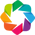

:QuadMesh   [variable,timepoint]   (observed (%))

In [4]:
ep.pl.missing_values_matrix(edata, width=700, height=400)

Drugs and procedures last from a start to an end; {func}`~ehrdata.io.omop.setup_interval_variables` marks the hours of every stay that they start in or cover.
The demo records antibiotics as pharmacy orders, by the RxNorm concept of the drug.
Its vocabulary tables do not name these concepts, so we list the drug concepts of the demo with an anti-infective ingredient, which the OMOP vocabulary's `CONCEPT_ANCESTOR` gives.
Body fluid samples come from `specimen`, which has no `visit_detail_id`, so ehrdata gives a sample to every stay of its person whose window holds it.

The demo has no infusion rates of vasopressors and no invasive ventilation, inputs that the SOFA score needs, and no urine output, which SOFA and KDIGO both read.

In [5]:
# RxNorm drugs of the demo with one of 24 anti-infective ingredients, such as vancomycin, cefepime or meropenem
# fmt: off
ANTIBIOTIC_DRUGS = [
    997892, 997997, 1703691, 1707346, 1707348, 1713694, 1714278, 1714279,
    1714303, 1736892, 1742257, 1742258, 1742282, 1742284, 1754996, 1797515,
    1836433, 1836434, 1836452, 19019003, 19031216, 19057568, 19073183, 19073777,
    19075378, 19075380, 19075429, 19076953, 19077601, 19077631, 19079960, 19098454,
    19102518, 19115197, 19135631, 35603389, 35603401, 35604327, 35605311, 35605312,
    35605343, 35606001, 35606004, 35606006, 35606008, 35606521, 37497785, 40087247,
    40164955, 40221350, 40221352, 40221353, 40221358, 46275430, 46275446, 46275516,
    46275520, 46275616, 46275622, 46276327, 46287312, 46287328, 46287330, 46287335,
    46287338, 46287345, 46287349, 46287354, 46287382, 46287384, 46287440, 46287449,
    46287450,
]
# fmt: on
antibiotics = ed.io.omop.setup_interval_variables(
    edata,
    data_tables="drug_exposure",
    data_field_to_keep="is_present",
    concept_ids=ANTIBIOTIC_DRUGS,
    keep_date="start",
    **grid,
)
samples = ed.io.omop.setup_variables(edata, data_tables="specimen", data_field_to_keep="is_present", **grid)
for name, other in {"antibiotics": antibiotics, "samples": samples}.items():
    print(f"{name:12} {other.X.shape}, {int(np.isfinite(other.X).sum())} observed cells")

antibiotics  (114, 73, 216), 470 observed cells
samples      (114, 15, 216), 49 observed cells


## ICU labels with ehrapy

The ehrapy tools read every input by name, as a variable of `X` or of a 3D layer, or as a key of `obsm` with a value per stay and hour.
They count windows in timepoints, here hours, and take and give times in `.obs` as positions on the grid, 0 for its first hour: hour `h` of a stay is position `h + grid["num_intervals_before"]`, as the grid starts 48 hours before the stay.
{func}`~ehrapy.tools.mark_events` marks the hours with antibiotics or samples, of any of their concepts, and these markers go into `obsm` of `edata`, together with the Glasgow Coma Scale, the sum of its three parts.

In [6]:
for other, key in ((antibiotics, "antibiotics"), (samples, "samples")):
    ep.tl.mark_events(other, key_added=key)
    edata.obsm[key] = other.obsm[key]
    print(f"{key:12} in {other.obs[f'{key}_first'].notna().sum()} stays")
parts = [edata[:, f"gcs_{part}"].X[:, 0, :] for part in ("eye", "verbal", "motor")]
edata.obsm["gcs"] = parts[0] + parts[1] + parts[2]

antibiotics  in 89 stays
samples      in 33 stays


### SOFA

{func}`~ehrapy.tools.sofa` scores the six organs at every hour and sums the worst score of each over the last 24 hours {cite}`Vincent1996`.
It writes the total to `obsm["sofa"]` and the organs to `obsm["sofa_<organ>"]`.
Without vasopressors, the cardiovascular score reads the mean arterial pressure alone and reaches 1 at most, the renal score reads creatinine alone, and without invasive ventilation respiration reaches 2 at most.
An organ without any input counts as 0, as ricu does, so SOFA is lower here than with the full inputs.

In [7]:
ep.tl.sofa(
    edata,
    pao2="po2",
    fio2="fio2",
    platelets="plt",
    bilirubin="bili",
    mean_arterial_pressure="map",
    gcs="gcs",
    creatinine="crea",
)
sofa = edata.obsm["sofa"]
print(f"SOFA scored in {np.isfinite(sofa).mean():.0%} of the stay-hours")
print(f"highest SOFA of a stay: median {np.nanmedian(np.nanmax(sofa, axis=1)):.0f}")

SOFA scored in 44% of the stay-hours
highest SOFA of a stay: median 6


### Suspected infection and Sepsis-3

ricu suspects an infection on MIMIC-IV where antibiotics and a body fluid sample come close in time.
{func}`~ehrapy.tools.mark_sustained_events` keeps the hours from which antibiotics go on for 72 hours, or until death, without a gap of more than 24 hours, YAIB's continuous antibiotic treatment.
{func}`~ehrapy.tools.mark_paired_events` keeps those followed by a sample within 24 hours and the samples followed by them within 72 hours, and writes the position of the first such hour to `obs["suspected_infection_first"]`.
{func}`~ehrapy.tools.sepsis3` then looks for a rise of the SOFA score by 2 points from 48 hours before to 24 hours after it {cite}`Singer2016`.

In [8]:
death_hour = (edata.obs["death_datetime"] - edata.obs["visit_detail_start_datetime"]).dt.total_seconds() / 3600
edata.obs["death"] = death_hour + grid["num_intervals_before"]  # a position on the grid, which starts 48 hours earlier
ep.tl.mark_sustained_events(edata, "antibiotics", duration=72, max_gap=24, end_key="death", key_added="abx_cont")
ep.tl.mark_paired_events(edata, "abx_cont", "samples", a_to_b=24, b_to_a=72, key_added="suspected_infection")
ep.tl.sepsis3(edata, infection_key="suspected_infection_first")

onset = edata.obs["sepsis3_onset"] - grid["num_intervals_before"]  # hours from the start of the stay
print(f"continuous antibiotics: {edata.obs['abx_cont_first'].notna().sum()} stays")
print(f"suspected infection:    {edata.obs['suspected_infection_first'].notna().sum()} stays")
print(
    f"Sepsis-3:               {edata.obs['sepsis3'].sum()} stays, onset before the stay in {(onset < 0).sum()}, later in {(onset >= 0).sum()}"
)

continuous antibiotics: 13 stays
suspected infection:    2 stays
Sepsis-3:               2 stays, onset before the stay in 1, later in 1


### KDIGO

{func}`~ehrapy.tools.kdigo` stages acute kidney injury at every hour {cite}`KDIGO2012`: by creatinine, against the lowest value of the last 48 hours and of the last 7 days, and by the urine output per kg over 6, 12 and 24 hours.
Without urine output, the demo is staged by creatinine alone.
{func}`~ehrapy.tools.mark_events` with `ignore_zero` then gives the first hour at stage 1 or more.

In [9]:
ep.tl.kdigo(edata, creatinine="crea")
ep.tl.mark_events(edata, "kdigo", ignore_zero=True, key_added="aki")

highest = np.nanmax(np.where(np.isnan(edata.obsm["kdigo"]), -1, edata.obsm["kdigo"]), axis=1)
stages, counts = np.unique(highest[highest >= 0].astype(int), return_counts=True)
print("highest KDIGO stage of a stay:", dict(zip(stages.tolist(), counts.tolist(), strict=True)))
print(f"stage 1 or more: {edata.obs['aki_first'].notna().sum()} stays")

highest KDIGO stage of a stay: {0: 70, 1: 28, 2: 5, 3: 11}
stage 1 or more: 44 stays


### The labels of a stay

{func}`~ehrapy.plot.timeseries` shows the scores of every hour, from `obsm`, and the events of a stay, whose positions are in `obs`.
Below every stay, a row of ticks marks the hours of every marker: the antibiotics, the continuous antibiotic treatment, the samples and the suspected infection, which needs the two together.
The KDIGO stage by creatinine is known only at the hours with a creatinine value, so the plot shows the worst stage of the last 24 hours.
These are the two stays with Sepsis-3.

In [10]:
edata.obsm["kdigo_24h"] = pd.DataFrame(edata.obsm["kdigo"].T).rolling(24, min_periods=1).max().to_numpy().T

ep.pl.timeseries(
    edata,
    obs_names=edata.obs_names[edata.obs["sepsis3"].astype(bool)],
    var_names=[],
    obsm_keys=["sofa", "kdigo_24h"],
    events=["suspected_infection_first", "sepsis3_onset", "aki_first", "death"],
    markers=["antibiotics", "abx_cont", "samples", "suspected_infection"],
    time_key="interval_step",
    xlabel="hour of the stay",
    ylabel="score",
    width=700,
    height=250,
)

:Layout
   .Overlay.Time_series_for_observation_5824 :Overlay
      .Curve.Sofa                      :Curve   [time]   (value,variable)
      .Curve.Kdigo_24h                 :Curve   [time]   (value,variable)
      .Curve.Suspected_infection_first :Curve   [time]   (value,variable)
      .Curve.Sepsis3_onset             :Curve   [time]   (value,variable)
   .Overlay.I                                :Overlay
      .Spikes.Antibiotics         :Spikes   [time]
      .Spikes.Abx_cont            :Spikes   [time]
      .Spikes.Samples             :Spikes   [time]
      .Spikes.Suspected_infection :Spikes   [time]
      .Curve.I                    :Curve   [time]   (row)
      .Curve.II                   :Curve   [time]   (row)
   .Overlay.Time_series_for_observation_9541 :Overlay
      .Curve.Sofa                      :Curve   [time]   (value,variable)
      .Curve.Kdigo_24h                 :Curve   [time]   (value,variable)
      .Curve.Suspected_infection_first :Curve   [time]   (value,variable)
      .Curve.Sepsis3_onset             :Curve   [time]   (value,variable)
      .Curve.Aki_first                 :Curve   [time]   (value,variable)
   .Overlay.II                               :Overlay
      .Spikes.Antibiotics         :Spikes   [time]
      .Spikes.Abx_cont            :Spikes   [time]
      .Spikes.Samples             :Spikes   [time]
      .Spikes.Suspected_infection :Spikes   [time]
      .Curve.I                    :Curve   [time]   (row)
      .Curve.II                   :Curve   [time]   (row)
      .Curve.III                  :Curve   [time]   (row)

## Predicting acute kidney injury

The task: from the first 24 hours of the hourly variables, predict whether acute kidney injury, KDIGO stage 1 or more, begins later in the first week, among the stays without it before hour 24.
{func}`~ehrapy.ml.split` puts every stay into a training, a tuning or a held-out set, and an {class}`~ehrapy.ml.Task` names the label and the observation window, as positions on the grid.

In [11]:
aki_hour = edata.obs["aki_first"] - grid["num_intervals_before"]
# missing for stays with AKI before hour 24
edata.obs["aki_after_24h"] = np.where(aki_hour < 24, np.nan, aki_hour >= 24)
ep.ml.split(edata, stratify="aki_after_24h")
task = ep.ml.Task("aki_after_24h", prediction_time=24 + grid["num_intervals_before"], observation_window=24)
model_variables = [var for var in VARIABLES if not var.startswith("gcs_")]
labeled = edata.obs["aki_after_24h"].notna()
(
    edata.obs[labeled]
    .groupby("split", observed=True)["aki_after_24h"]
    .agg(["size", "sum"])
    .rename(columns={"size": "stays", "sum": "with AKI"})
)

,stays,with AKI
split,,
train,61,12.0
tuning,13,2.0
held_out,13,3.0


{func}`~ehrapy.ml.fit` takes any PyTorch module that maps the values, whether they were observed, the time since their last observation and the static covariates to an embedding.
We wrap the GRU-D backbone of [PyPOTS](https://github.com/WenjieDu/PyPOTS), which decays missing values towards the mean and its hidden state with the time since the last observation {cite}`che2018recurrent`.
ehrapy carries the values forward and standardizes them with the training set, so their mean is 0, and gives the time since the last observation as a fraction of the window, which the backbone reads in hours.
Its last hidden state is the embedding, as in the GRU-D classifier of PyPOTS.
ehrapy then trains it with early stopping on the tuning set and evaluates it on the held-out set.

In [12]:
class GRUD(torch.nn.Module):
    def __init__(self, n_steps: int, n_features: int, hidden_size: int = 32):
        super().__init__()
        self.n_steps = n_steps
        self.backbone = BackboneGRUD(n_steps, n_features, hidden_size)
        self.register_buffer("empirical_mean", torch.zeros(n_features))

    def forward(self, values, mask, time_since_observed, static):
        deltas = time_since_observed * self.n_steps
        return self.backbone(values * mask, mask, deltas, self.empirical_mean, values)[1]


torch.manual_seed(0)
grud = ep.ml.fit(
    edata,
    task,
    model=GRUD(task.observation_window, len(model_variables)),
    var_names=model_variables,
    trainer=ep.ml.Trainer(max_epochs=50, device="cpu"),
)
ep.ml.predict(edata, grud, key_added="grud")
ep.ml.evaluate(edata, task, key="grud", n_bootstrap=200).loc[["auroc", "auprc", "brier"]].round(3)

,value,ci_lower,ci_upper
metric,,,
auroc,0.400,0.096,0.732
auprc,0.241,0.091,0.592
brier,0.192,0.096,0.319


The model predicts the risk at hour 24 from the first 24 hours of a stay.
For the held-out stays with acute kidney injury after hour 24, and the two without it that the model ranks highest, the plot shows the predicted risk next to the creatinine, the KDIGO stage and the onset of acute kidney injury in the first week.

In [13]:
edata.obs["prediction_time"] = task.prediction_time  # a position on the grid, at hour 24
held_out = edata.obs[(edata.obs["split"] == "held_out") & labeled]
shown = pd.concat(
    [held_out[held_out["aki_after_24h"] == 1], held_out[held_out["aki_after_24h"] == 0].nlargest(2, "grud")]
).sort_values("grud", ascending=False)
hv.Layout(
    [
        ep.pl.timeseries(
            edata,
            obs_names=name,
            var_names="crea",
            obsm_keys="kdigo_24h",
            events=["prediction_time", "aki_first"],
            tem_names=slice(task.prediction_time - task.observation_window, None),
            time_key="interval_step",
            xlabel="hour of the stay",
            title=f"{name}: predicted risk {stay.grud:.2f}, acute kidney injury after hour 24: {'yes' if stay.aki_after_24h else 'no'}",
            width=700,
            height=200,
        )
        for name, stay in shown.iterrows()
    ]
).cols(1)

:Layout
   .Overlay.A_7265_colon_predicted_risk_0_full_stop_39_comma_acute_kidney_injury_after_hour_24_colon_no   :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
   .Overlay.A_6114_colon_predicted_risk_0_full_stop_33_comma_acute_kidney_injury_after_hour_24_colon_no   :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
   .Overlay.A_9541_colon_predicted_risk_0_full_stop_22_comma_acute_kidney_injury_after_hour_24_colon_yes  :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
      .Curve.Aki_first       :Curve   [time]   (value,variable)
   .Overlay.A_5610_colon_predicted_risk_0_full_stop_22_comma_acute_kidney_injury_after_hour_24_colon_yes  :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
      .Curve.Aki_first       :Curve   [time]   (value,variable)
   .Overlay.A_12952_colon_predicted_risk_0_full_stop_20_comma_acute_kidney_injury_after_hour_24_colon_yes :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
      .Curve.Aki_first       :Curve   [time]   (value,variable)

With 100 patients, the held-out set has only a few stays, so these metrics vary widely with the split and the seed; the tutorial shows the workflow rather than a result.

The hidden cell below fits the same model with PyPOTS alone, on the same split, observation window and standardization.

In [14]:
from pypots.classification import GRUD as PyPOTSGRUD
from pypots.optim import Adam
from pypots.utils.logging import logger
from pypots.utils.random import set_random_seed
from sklearn.metrics import average_precision_score, roc_auc_score

logger.disabled = True  # PyPOTS logs its seed and that no model files are saved
split, y = edata.obs["split"].to_numpy(), edata.obs["aki_after_24h"].to_numpy()
train, tuning, held_out = ((split == name) & ~np.isnan(y) for name in ("train", "tuning", "held_out"))
window = edata[:, model_variables, task.prediction_time - task.observation_window : task.prediction_time].X
X = np.moveaxis(np.asarray(window, dtype=np.float64), 1, 2)  # stays x hours x variables, as PyPOTS takes it
mean, std = np.nanmean(X[train], axis=(0, 1)), np.nanstd(X[train], axis=(0, 1))
X = (X - np.nan_to_num(mean)) / np.where(np.isnan(std) | (std == 0), 1.0, std)

set_random_seed(0)
model = PyPOTSGRUD(
    n_steps=X.shape[1],
    n_features=X.shape[2],
    n_classes=2,
    rnn_hidden_size=32,
    batch_size=128,
    epochs=50,
    patience=10,
    optimizer=Adam(lr=1e-3),
    device="cpu",
    verbose=False,
)
model.fit({"X": X[train], "y": y[train].astype(int)}, {"X": X[tuning], "y": y[tuning].astype(int)})
probability = model.predict({"X": X[held_out]})["classification_proba"][:, 1]
print(
    f"PyPOTS alone: AUROC {roc_auc_score(y[held_out], probability):.3f}, "
    f"AUPRC {average_precision_score(y[held_out], probability):.3f}"
)

PyPOTS alone: AUROC 0.300, AUPRC 0.216


## Conclusion

ehrdata turned the OMOP CDM into hourly variables of the ICU stays, and ehrapy derived the SOFA score, the Sepsis-3 onset and the KDIGO stage from them, and predicted acute kidney injury with a PyPOTS model.
The same code reads any OMOP CDM: with vasopressor rates, ventilation and urine output in the CDM, the labels use all their inputs.